a: Load and Inspect the Data

In [33]:
# Uploading the .csv file
from google.colab import files
files.upload()

Saving superstore_unclean - superstore_unclean.csv to superstore_unclean - superstore_unclean (1).csv


{'superstore_unclean - superstore_unclean (1).csv': b'Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit\r\n2046,US-2023-133592,2023-12-31,2024-01-07,Standard Class,KM-16375,Katherine Murray,Home Office,United States,Providence,Rhode Island,2908,East,OFF-PA-10003228,Office Supplies,Paper,Xerox 1917,195.64,4,0,91.9508\r\n4701,US-2025-101525,2025-05-01,2025-05-04,Second Class,CM-12235,Chris McAfee,Consumer,United States,Little Rock,Arkansas,72209,South,OFF-PA-10001497,Office Supplies,Paper,Xerox 1914,109.92,2,0,53.8608\r\n4964,US-2025-167472,2025-06-06,2025-06-07,First Class,CK-12595,Clytie Kelty,Consumer,United States,Little Rock,Arkansas,72209,South,TEC-AC-10003174,Technology,Accessories,Plantronics S12 Corded Telephone Headset System,323.37,3,0,129.348\r\n34,US-2023-103366,2023-01-15,2023-01-17,First Class,EH-13990,Erica Hackn

Step 1: Import Pandas

In [36]:
import pandas as pd

Step 2: Load Dataset

In [37]:
df = pd.read_csv('superstore_unclean - superstore_unclean.csv')

Step 3: View First Five Rows

In [38]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,2046,US-2023-133592,2023-12-31,2024-01-07,Standard Class,KM-16375,Katherine Murray,Home Office,United States,Providence,...,2908,East,OFF-PA-10003228,Office Supplies,Paper,Xerox 1917,195.64,4,0.0,91.9508
1,4701,US-2025-101525,2025-05-01,2025-05-04,Second Class,CM-12235,Chris McAfee,Consumer,United States,Little Rock,...,72209,South,OFF-PA-10001497,Office Supplies,Paper,Xerox 1914,109.92,2,0.0,53.8608
2,4964,US-2025-167472,2025-06-06,2025-06-07,First Class,CK-12595,Clytie Kelty,Consumer,United States,Little Rock,...,72209,South,TEC-AC-10003174,Technology,Accessories,Plantronics S12 Corded Telephone Headset System,323.37,3,0.0,129.3480
3,34,US-2023-103366,2023-01-15,2023-01-17,First Class,EH-13990,Erica Hackney,Consumer,United States,Roswell,...,30076,South,TEC-AC-10003628,Technology,Accessories,Logitech 910-002974 M325 Wireless Mouse for We...,149.95,5,0.0,65.9780
4,2927,US-2024-124219,2024-08-07,2024-08-08,First Class,KW-16570,Kelly Williams,Consumer,United States,Kirkwood,...,63122,Central,FUR-FU-10000305,Furniture,Furnishings,"Tenex V2T-RE Standard Weight Series Chair Mat,...",212.94,3,0.0,34.0704


Step 4: Dataset Size

In [39]:
df.shape

(10214, 21)

Step 5: Data Types

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10214 entries, 0 to 10213
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10214 non-null  int64  
 1   Order ID        10214 non-null  object 
 2   Order Date      10214 non-null  object 
 3   Ship Date       10214 non-null  object 
 4   Ship Mode       10214 non-null  object 
 5   Customer ID     10214 non-null  object 
 6   Customer Name   10214 non-null  object 
 7   Segment         10214 non-null  object 
 8   Country/Region  10214 non-null  object 
 9   City            10214 non-null  object 
 10  State/Province  10214 non-null  object 
 11  Postal Code     10184 non-null  object 
 12  Region          10214 non-null  object 
 13  Product ID      10214 non-null  object 
 14  Category        10214 non-null  object 
 15  Sub-Category    10214 non-null  object 
 16  Product Name    10214 non-null  object 
 17  Sales           10194 non-null 

Step 6: Summary Statistics

In [42]:
df.describe()
# Notice that Sales is missing because it is stored as text instead of numbers.

,Row ID,Quantity,Discount,Profit
count,10214.000000,10214.000000,10214.000000,10214.000000
mean,5096.372528,3.781868,0.155452,28.641109
std,2943.754048,2.244482,0.206313,232.241551
min,1.000000,-8.000000,0.000000,-6599.978000
25%,2547.250000,2.000000,0.000000,1.753775
50%,5095.500000,3.000000,0.200000,8.687750
75%,7645.750000,5.000000,0.200000,29.282175
max,10194.000000,14.000000,0.800000,8399.976000


b: Clean the Data

Step 1: Remove Duplicate Rows

In [43]:
df.duplicated().sum()
df = df.drop_duplicates()

Step 2: Convert Sales to Numeric

In [48]:
df['Sales'] = df['Sales'].astype(str).str.replace('$','',regex=False)
df['Sales'] = df['Sales'].astype(str).str.replace(',','',regex=False)
df['Sales'] = pd.to_numeric(df['Sales'],errors='coerce')

Step 3: Convert Dates

In [49]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'], format='mixed', errors='coerce'
)
df['Ship Date'] = pd.to_datetime(
    df['Ship Date'], format='mixed', errors='coerce'
)

Step 4: Find Missing Values

In [50]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country/Region,0
City,0


Step 5: Handle Missing Values

In [51]:
# For Sales
df = df.dropna(subset=['Sales'])

In [52]:
# For Postal Code
df['Postal Code'] = df['Postal Code'].fillna("Unknown")

/tmp/ipykernel_2086/97620254.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Postal Code'] = df['Postal Code'].fillna("Unknown")


Step 6: Standardize Text

In [53]:
df['Ship Mode'] = df['Ship Mode'].str.strip().str.title()
df['Region'] = df['Region'].str.strip().str.title()

/tmp/ipykernel_2086/2786549303.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Ship Mode'] = df['Ship Mode'].str.strip().str.title()
/tmp/ipykernel_2086/2786549303.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Region'] = df['Region'].str.strip().str.title()


Step 7: Impossible Values

In [54]:
# Negative Quantity
df[df['Quantity'] < 0]

# Shipping Before Ordering
df[df['Ship Date'] < df['Order Date']]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
218,3394,US-2024-134859,2024-10-04,2024-09-29,Standard Class,JK-16120,Julie Kriz,Home Office,United States,Philadelphia,...,19134,East,FUR-FU-10003623,Furniture,Furnishings,"DataProducts Ampli Magnifier Task Lamp, Black,",64.944,3,0.2,6.4944
612,3018,US-2024-165624,2024-08-23,2024-08-18,Standard Class,FH-14350,Fred Harton,Consumer,United States,Atlanta,...,30318,South,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.940,3,0.0,152.0232
2729,1644,US-2023-144624,2023-11-19,2023-11-14,Standard Class,JM-15865,John Murray,Consumer,United States,Jamestown,...,14701,East,TEC-PH-10002885,Technology,Phones,Apple iPhone 5,4548.810,7,0.0,1228.1787
2853,373,US-2023-110849,2023-04-18,2023-04-13,Standard Class,JL-15835,John Lee,Consumer,United States,Los Angeles,...,90049,West,OFF-AR-10000657,Office Supplies,Art,"Binney & Smith inkTank Desk Highlighter, Chise...",10.750,5,0.0,3.5475
3909,9582,US-2026-120404,2026-11-20,2026-11-15,Second Class,KH-16330,Katharine Harms,Corporate,United States,New York City,...,10035,East,TEC-PH-10001363,Technology,Phones,Apple iPhone 5S,569.990,1,0.0,170.9970
4901,758,US-2023-164182,2023-07-14,2023-07-09,Standard Class,ST-20530,Shui Tom,Consumer,United States,Philadelphia,...,19140,East,TEC-PH-10002070,Technology,Phones,Griffin GC36547 PowerJolt SE Lightning Charger,13.494,1,0.4,-2.2490
6873,7334,US-2026-145877,2026-04-01,2026-03-27,Second Class,AS-10090,Adam Shillingsburg,Consumer,United States,Springfield,...,65807,Central,OFF-EN-10001990,Office Supplies,Envelopes,Staple envelope,28.400,5,0.0,13.3480
8288,2495,US-2024-112130,2024-05-03,2024-04-28,Standard Class,SV-20785,Stewart Visinsky,Consumer,United States,Philadelphia,...,19140,East,OFF-AR-10001468,Office Supplies,Art,Sanford Prismacolor Professional Thick Lead Ar...,59.904,2,0.2,14.2272
8305,2531,US-2024-162607,2024-05-12,2024-05-07,Standard Class,RO-19780,Rose O'Brian,Consumer,United States,Seattle,...,98115,West,OFF-BI-10002949,Office Supplies,Binders,Prestige Round Ring Binders,14.592,3,0.2,4.9248


Stepp 8: Verify Cleaning

In [55]:
df.info()
df.shape
df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 10119 entries, 0 to 10213
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10119 non-null  int64         
 1   Order ID        10119 non-null  object        
 2   Order Date      10119 non-null  datetime64[ns]
 3   Ship Date       10119 non-null  datetime64[ns]
 4   Ship Mode       10119 non-null  object        
 5   Customer ID     10119 non-null  object        
 6   Customer Name   10119 non-null  object        
 7   Segment         10119 non-null  object        
 8   Country/Region  10119 non-null  object        
 9   City            10119 non-null  object        
 10  State/Province  10119 non-null  object        
 11  Postal Code     10119 non-null  object        
 12  Region          10119 non-null  object        
 13  Product ID      10119 non-null  object        
 14  Category        10119 non-null  object        
 15  Sub-Cat

,Row ID,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,10119.000000,10119,10119,10119.000000,10119.000000,10119.000000,10119.000000
mean,5097.744639,2025-04-29 10:59:35.452119808,2025-05-03 09:55:33.175214848,228.579092,3.781895,0.155266,28.675011
min,1.000000,2023-01-03 00:00:00,2023-01-07 00:00:00,0.556000,-8.000000,0.000000,-6599.978000
25%,2548.500000,2024-05-14 00:00:00,2024-05-19 00:00:00,17.280000,2.000000,0.000000,1.747950
50%,5098.000000,2025-06-25 00:00:00,2025-06-28 00:00:00,54.208000,3.000000,0.200000,8.694000
75%,7645.500000,2026-05-14 00:00:00,2026-05-18 00:00:00,209.534000,5.000000,0.200000,29.315200
max,10194.000000,2026-12-30 00:00:00,2027-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,2944.421131,NaN,NaN,620.549018,2.242812,0.206095,233.267470


c: Data Summarization

In [56]:
# Highest Sales by Sub-category
df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False)

,Sales
Sub-Category,
Chairs,334352.8690
Phones,326488.6120
Storage,222707.0740
Tables,207874.1420
Binders,206886.3130
Machines,189460.0610
Accessories,166273.1620
Copiers,150745.2900
Bookcases,114732.2453


In [57]:
# Sales by Segment
df.groupby('Segment')['Sales'].aggregate(['sum', 'mean', 'count'])

,sum,mean,count
Segment,,,
Consumer,1.161151e+06,221.805344,5235
Corporate,7.136321e+05,232.377768,3071
Home Office,4.382087e+05,241.703655,1813


In [58]:
# Category Count
df['Category'].value_counts()

,count
Category,
Office Supplies,6076
Furniture,2191
Technology,1852


In [59]:
# Profit Analysis
df.groupby('Sub-Category')['Profit'].sum().sort_values()
"""Business Insights
Technology-related products generally contribute higher sales.
Consumer segment usually contributes maximum revenue.
Some sub-categories may have high sales but low profit because of discounts.
Office Supplies generally have more orders but lower average sales."""

'Business Insights\nTechnology-related products generally contribute higher sales.\nConsumer segment usually contributes maximum revenue.\nSome sub-categories may have high sales but low profit because of discounts.\nOffice Supplies generally have more orders but lower average sales.'

d: Visualization

In [60]:
# Import Library
import matplotlib.pyplot as plt

Chart 1: Sales by Sub-category

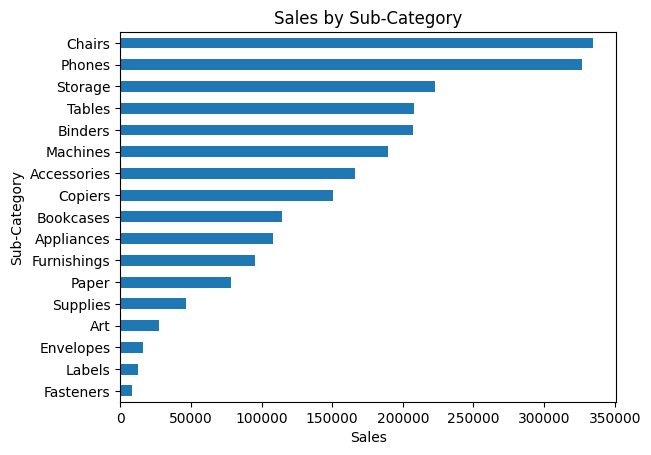

In [61]:
df.groupby('Sub-Category')['Sales'].sum().sort_values().plot(kind='barh')

plt.title("Sales by Sub-Category")
plt.xlabel("Sales")
plt.ylabel("Sub-Category")

plt.show()

Chart 2: Monthly Sales Trend

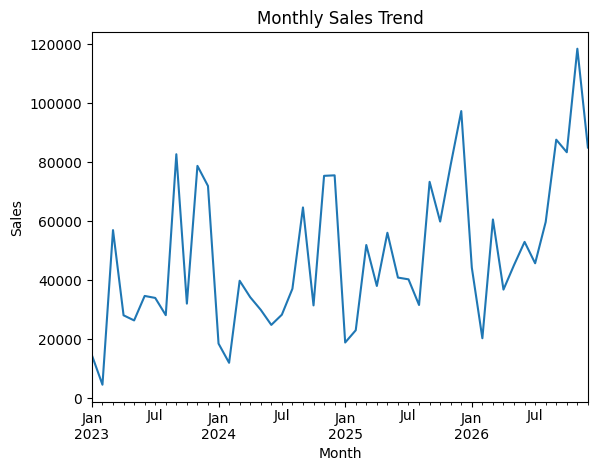

In [62]:
monthly = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()

monthly.plot(kind='line')

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.show()

Chart 3: Sales Distribution

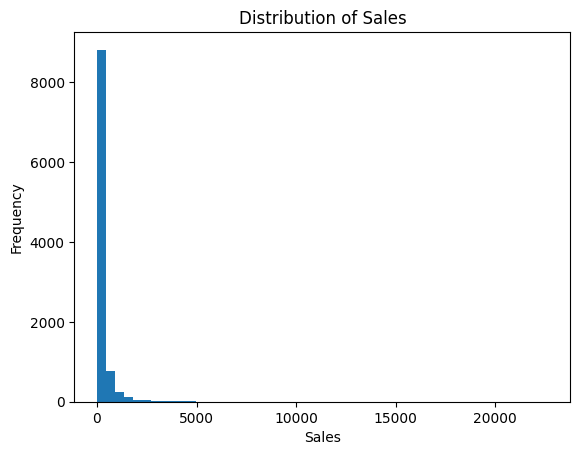

In [67]:
df['Sales'].plot(kind='hist', bins=50)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()